# Bayesian inference of the squeezing parameter (two-scheme version)

Updated copy of `bayesian_inference.ipynb`, which is left unchanged. Changes:

- the pasted copy of the old `simulate.py` is replaced by an import from `simulate.py`;
- homodyne is removed: the simulator now models only **joint** (idealized benchmark) and **heterodyne** (physical case), see Section 3.1;
- the NaN masking in the likelihood is dropped, since every shot now contains both quadratures;
- duplicate imports are merged into the first cell, and the empty last cell is removed.

The models, priors and MCMC settings are otherwise unchanged.

In [1]:
import numpyro
numpyro.set_host_device_count(4)  # run the 4 chains in parallel on CPU; must precede any JAX computation

import numpy as np
import pandas as pd
import jax
import jax.numpy as jnp
from jax import random
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS
import arviz as az
import matplotlib.pyplot as plt

from simulate import generate_covariance_matrix, reduce_to_accessible, sample_measurements, sample_calibration

C:\Users\kanci\OneDrive\Dokumenty\GitHub\Gaussian-State-Tomography-of-Hawking-Unruh-Toy-Radiation\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
r_true = 0.5

V = generate_covariance_matrix(r_true)
V_A = reduce_to_accessible(V)

samples = sample_measurements(
    V_A,
    n_samples=1000,
    noise_level=0.1,
    measurement_type="joint",
    key=jax.random.PRNGKey(0), # or random.key(0)
)

In [3]:
def model(X_obs):
    r = numpyro.sample("r", dist.Uniform(0, 1))
    V_est = generate_covariance_matrix(r)
    V_A_est = reduce_to_accessible(V_est) + 0.1**2 * jnp.eye(2)

    numpyro.sample("X_obs",dist.MultivariateNormal(loc=jnp.zeros(V_A_est.shape[0]), covariance_matrix=V_A_est), obs=X_obs)

In [4]:
rng_key = jax.random.PRNGKey(0)
kernel = NUTS(model)
mcmc = MCMC(
    kernel,
    num_warmup=1000,
    num_samples=2000,
)
mcmc.run(rng_key, X_obs=samples)
posterior_samples = mcmc.get_samples()["r"]

  0%|          | 0/3000 [00:00<?, ?it/s]

warmup:   5%|▌         | 150/3000 [00:00<00:12, 229.41it/s, 1 steps of size 1.85e+00. acc. prob=0.78]

warmup:  15%|█▌        | 451/3000 [00:00<00:03, 722.59it/s, 3 steps of size 2.17e+01. acc. prob=0.79]

warmup:  25%|██▌       | 761/3000 [00:00<00:01, 1194.43it/s, 1 steps of size 8.98e-01. acc. prob=0.79]

sample:  35%|███▌      | 1064/3000 [00:00<00:01, 1603.89it/s, 3 steps of size 1.03e+00. acc. prob=0.91]

sample:  45%|████▌     | 1359/3000 [00:01<00:00, 1928.23it/s, 3 steps of size 1.03e+00. acc. prob=0.92]

... (2 outputs left out)

sample:  76%|███████▌  | 2267/3000 [00:01<00:00, 2585.13it/s, 1 steps of size 1.03e+00. acc. prob=0.93]

sample:  86%|████████▌ | 2572/3000 [00:01<00:00, 2714.28it/s, 1 steps of size 1.03e+00. acc. prob=0.93]

sample:  96%|█████████▌| 2886/3000 [00:01<00:00, 2804.61it/s, 1 steps of size 1.03e+00. acc. prob=0.93]

sample: 100%|██████████| 3000/3000 [00:01<00:00, 1865.77it/s, 3 steps of size 1.03e+00. acc. prob=0.93]

array([[<Axes: title={'center': 'r'}>, <Axes: title={'center': 'r'}>]],
      dtype=object)

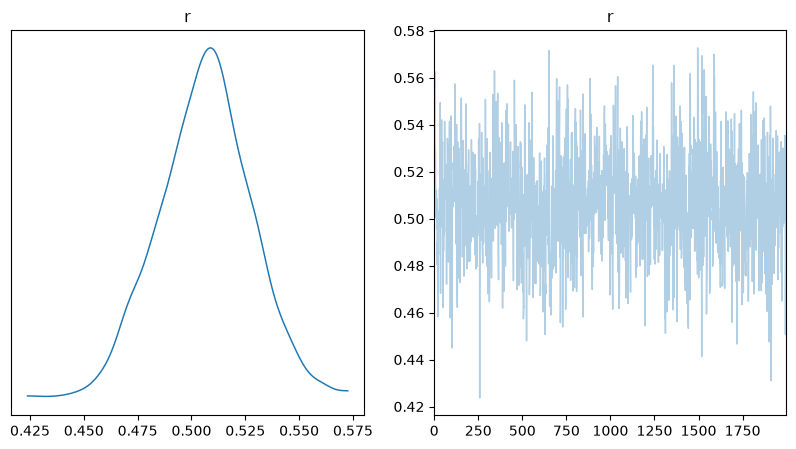

In [5]:
data = az.from_numpyro(mcmc)
az.plot_trace(data, compact=True, figsize=(10, 5))

In [6]:
posterior_mean = jnp.mean(posterior_samples)
posterior_mean

Array(0.50621134, dtype=float32)

***

In [7]:
r_true = 0.5
noise_true = 1.0
n_samples = 1000

rng = jax.random.PRNGKey(0)

# Full two-mode covariance
V = generate_covariance_matrix(r_true)
V_A = reduce_to_accessible(V)

samples = sample_measurements(
    V_A,
    n_samples=1000,
    noise_level=noise_true,
    measurement_type="joint",
    key=rng, # or random.key(0)
)

In [8]:
def model(X_obs):
    r = numpyro.sample("r", dist.Uniform(0.0, 1.0))
    noise = numpyro.sample("noise", dist.HalfNormal(1.0))

    V_est = generate_covariance_matrix(r)
    V_A_est = reduce_to_accessible(V_est) + noise**2 * jnp.eye(2)

    numpyro.sample("X_obs",dist.MultivariateNormal(loc=jnp.zeros(V_A_est.shape[0]), covariance_matrix=V_A_est), obs=X_obs)

In [9]:
rng_key = jax.random.PRNGKey(0)
kernel = NUTS(model, target_accept_prob=0.9)
mcmc = MCMC(
    kernel,
    num_warmup=1000,
    num_samples=2000,
    num_chains=4
)
mcmc.run(rng_key, X_obs=samples)

posterior_samples = mcmc.get_samples()
r_samples = posterior_samples["r"]
noise_samples = posterior_samples["noise"]

  0%|          | 0/3000 [00:00<?, ?it/s]

Compiling.. :   0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

Compiling.. :   0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

Compiling.. :   0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

Compiling.. :   0%|          | 0/3000 [00:00<?, ?it/s]

Running chain 0:   0%|          | 0/3000 [00:01<?, ?it/s]

Running chain 1:   0%|          | 0/3000 [00:01<?, ?it/s]

Running chain 2:   0%|          | 0/3000 [00:01<?, ?it/s]

Running chain 0:   5%|▌         | 150/3000 [00:01<00:06, 438.39it/s]

Running chain 2:   5%|▌         | 150/3000 [00:01<00:06, 439.87it/s]

Running chain 3:   5%|▌         | 150/3000 [00:01<00:07, 373.75it/s]

Running chain 2:  10%|█         | 300/3000 [00:02<00:04, 548.90it/s]

Running chain 1:   5%|▌         | 150/3000 [00:02<00:10, 261.21it/s]

Running chain 0:  10%|█         | 300/3000 [00:02<00:06, 396.36it/s]

... (74 outputs left out)

Running chain 1:  90%|█████████ | 2700/3000 [00:09<00:00, 326.03it/s]

Running chain 1:  95%|█████████▌| 2850/3000 [00:09<00:00, 343.10it/s]

Running chain 1: 100%|██████████| 3000/3000 [00:10<00:00, 330.34it/s]

Running chain 1: 100%|██████████| 3000/3000 [00:10<00:00, 294.51it/s]

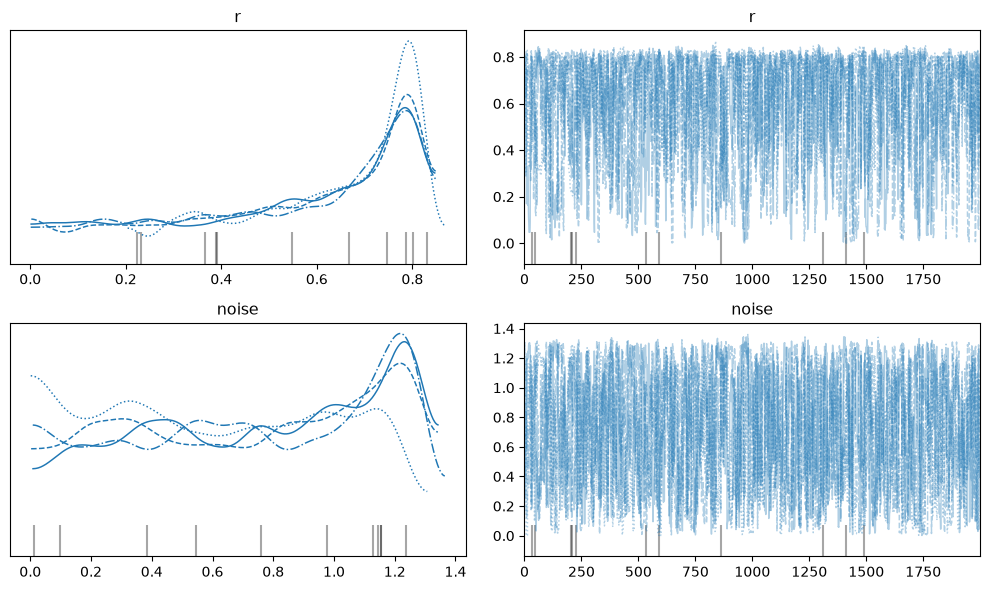

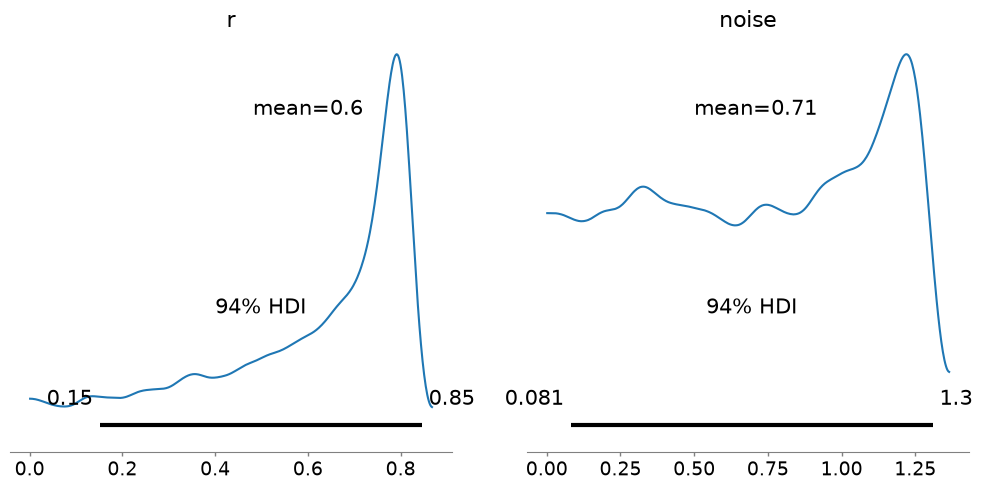

C:\Users\kanci\AppData\Local\Temp\ipykernel_20512\993155245.py:32: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


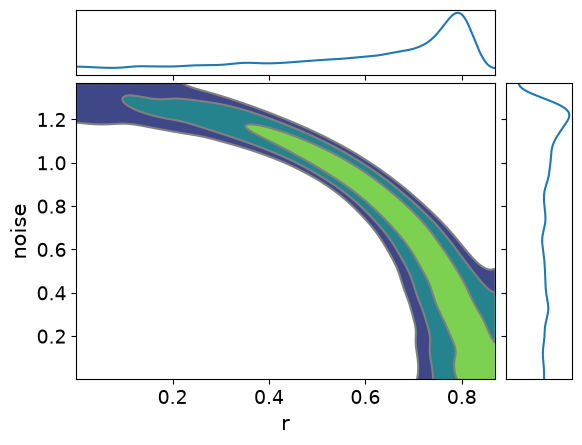

In [10]:
data = az.from_numpyro(mcmc)

az.plot_trace(
    data,
    var_names=["r", "noise"],
    compact=True,
    figsize=(10, 6)
)

plt.tight_layout()
plt.show()


az.plot_posterior(
    data,
    var_names=["r", "noise"],
    ref_val=None,
    figsize=(10, 5)
)

plt.tight_layout()
plt.show()


az.plot_pair(
    data,
    var_names=["r", "noise"],
    kind="kde",
    marginals=True
)

plt.tight_layout()
plt.show()


In [11]:
summary = az.summary(
    data,
    var_names=["r", "noise"],
    hdi_prob=0.90
)

print(summary)

        mean     sd  hdi_5%  hdi_95%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
r      0.600  0.220   0.239    0.844      0.008    0.005     770.0    1176.0   
noise  0.708  0.392   0.141    1.307      0.013    0.005     849.0    1083.0   

       r_hat  
r       1.02  
noise   1.02  


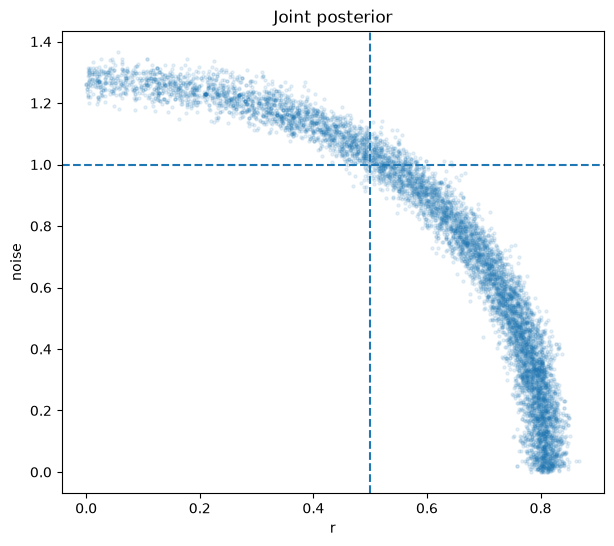

In [12]:
plt.figure(figsize=(7, 6))

plt.scatter(
    jnp.array(posterior_samples["r"]),
    jnp.array(posterior_samples["noise"]),
    alpha=0.1,
    s=5
)

plt.axvline(r_true, linestyle="--")
plt.axhline(noise_true, linestyle="--")

plt.xlabel("r")
plt.ylabel("noise")
plt.title("Joint posterior")

plt.show()

In [13]:
posterior_samples = mcmc.get_samples()

r_samples = posterior_samples["r"]
noise_samples = posterior_samples["noise"]

total_variance = (
    jnp.cosh(2 * r_samples)
    + noise_samples**2
)

print("Posterior mean total variance:",
      float(jnp.mean(total_variance)))

print("True total variance:",
      float(jnp.cosh(2 * r_true) + noise_true**2))

Posterior mean total variance: 2.627213954925537
True total variance: 2.5430805683135986


When both the squeezing parameter (r) and detector noise ($\sigma$) are treated as unknown, Bayesian inference successfully recovers the total observed variance. However, (r) and ($\sigma$) are only weakly identifiable individually because both parameters contribute to the same isotropic variance term

***
## Signal + vacuum calibration, joint and heterodyne

In [14]:
r_true = 0.5
noise_true = 1.0
n_samples = 1000
n_calibration = 1000
seed = 0
key_signal, key_cal = random.split(random.key(seed))
# Accessible one-mode covariance
V = generate_covariance_matrix(r_true)
V_A = reduce_to_accessible(V)

print("True r:", r_true)
print("True detector noise:", noise_true)
print("Accessible covariance:\n", V_A)

measurement_types = ["joint", "heterodyne"]

datasets = {}

for i, mt in enumerate(measurement_types):

    # Independent keys for every signal/calibration run
    key_signal_i, key_cal_i = random.split(
        random.fold_in(key_signal, i)
    )

    # Signal data: state + measurement effects + detector noise
    X_obs = sample_measurements(
        V_A,
        n_samples=n_samples,
        noise_level=noise_true,
        measurement_type=mt,
        key=key_signal_i,
    )

    # Vacuum calibration: no unknown squeezing signal
    calibration_data = sample_calibration(
        n_calibration=n_calibration,
        noise_level=noise_true,
        measurement_type=mt,
        key=key_cal_i,
        source="vacuum",
    )

    datasets[mt] = {
        "X_obs": X_obs,
        "calibration_data": calibration_data,
    }

    print(f"\n{mt}")
    print("Signal shape:", X_obs.shape)
    print("Calibration shape:", calibration_data.shape)


True r: 0.5
True detector noise: 1.0
Accessible covariance:
 [[1.5430806 0.       ]
 [0.        1.5430806]]

joint
Signal shape: (1000, 2)
Calibration shape: (1000, 2)

heterodyne
Signal shape: (1000, 2)
Calibration shape: (1000, 2)


In [15]:
def make_model(measurement_type):

    mt = measurement_type

    def model(X_obs, calibration_data):
        r = numpyro.sample("r", dist.Uniform(0.0, 1.0))
        noise = numpyro.sample("noise", dist.HalfNormal(1.0))

        V_est = generate_covariance_matrix(r)
        V_A_est = reduce_to_accessible(V_est)

        state_variance = V_A_est[0, 0]

        # Heterodyne has one extra unit of measurement noise
        measurement_offset = 1.0 if mt == "heterodyne" else 0.0

        signal_variance = (state_variance + measurement_offset + noise**2)
        signal_dist = dist.Normal(loc=0.0, scale=jnp.sqrt(signal_variance))

        # Signal likelihood: both quadratures are observed in every shot
        numpyro.factor("signal_likelihood", jnp.sum(signal_dist.log_prob(X_obs)))

        # Vacuum calibration likelihood
        # Vacuum state variance is 1 per quadrature.
        # Heterodyne adds another unit of measurement noise.
        calibration_offset = 2.0 if mt == "heterodyne" else 1.0
        calibration_variance = calibration_offset + noise**2

        calibration_dist = dist.Normal(loc=0.0, scale=jnp.sqrt(calibration_variance))

        numpyro.factor(
            "calibration_likelihood",
            jnp.sum(calibration_dist.log_prob(calibration_data))
        )

    return model

In [16]:
results = {}

for i, mt in enumerate(measurement_types):

    print(f"\n{'=' * 55}")
    print(f"Running inference: {mt}")
    print(f"{'=' * 55}")

    model_mt = make_model(mt)

    kernel = NUTS(
        model_mt,
        target_accept_prob=0.9
    )

    mcmc = MCMC(
        kernel,
        num_warmup=1000,
        num_samples=2000,
        num_chains=4,
        progress_bar=True,
    )

    run_key = random.fold_in(random.key(100), i)

    mcmc.run(
        run_key,
        X_obs=datasets[mt]["X_obs"],
        calibration_data=datasets[mt]["calibration_data"],
    )

    results[mt] = mcmc

    # Diagnostics
    idata = az.from_numpyro(mcmc)

    print(f"\nPosterior summary: {mt}")

    print(
        az.summary(
            idata,
            var_names=["r", "noise"],
            hdi_prob=0.90,
        )
    )


Running inference: joint


  0%|          | 0/3000 [00:00<?, ?it/s]

Compiling.. :   0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

Compiling.. :   0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

... (33 outputs left out)


Running chain 1: 100%|██████████| 3000/3000 [00:01<00:00, 1860.28it/s] 


Running chain 2: 100%|██████████| 3000/3000 [00:01<00:00, 1850.81it/s] 


Running chain 3: 100%|██████████| 3000/3000 [00:01<00:00, 1841.69it/s] 


Posterior summary: heterodyne
        mean     sd  hdi_5%  hdi_95%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
r      0.501  0.065   0.398    0.607      0.001    0.001    3410.0    2958.0   
noise  1.026  0.048   0.946    1.104      0.001    0.001    2992.0    3227.0   

       r_hat  
r        1.0  
noise    1.0  


In [17]:
summary_rows = []

for mt, mcmc in results.items():

    posterior = mcmc.get_samples()

    r_samples = np.asarray(posterior["r"])
    noise_samples = np.asarray(posterior["noise"])

    r_ci = np.percentile(r_samples, [5, 95])
    noise_ci = np.percentile(noise_samples, [5, 95])

    summary_rows.append({
        "measurement": mt,
        "r_mean": r_samples.mean(),
        "r_sd": r_samples.std(),
        "r_90%_low": r_ci[0],
        "r_90%_high": r_ci[1],
        "noise_mean": noise_samples.mean(),
        "noise_sd": noise_samples.std(),
        "noise_90%_low": noise_ci[0],
        "noise_90%_high": noise_ci[1],
    })

import pandas as pd

summary_df = pd.DataFrame(summary_rows)

print("\nTrue r:", r_true)
print("True noise:", noise_true)

print("\nComparison of measurement schemes:")
print(summary_df.round(3).to_string(index=False))


True r: 0.5
True noise: 1.0

Comparison of measurement schemes:
measurement  r_mean  r_sd  r_90%_low  r_90%_high  noise_mean  noise_sd  noise_90%_low  noise_90%_high
      joint   0.491 0.046      0.410       0.562       1.004     0.032          0.952           1.057
 heterodyne   0.501 0.065      0.387       0.599       1.026     0.048          0.946           1.104


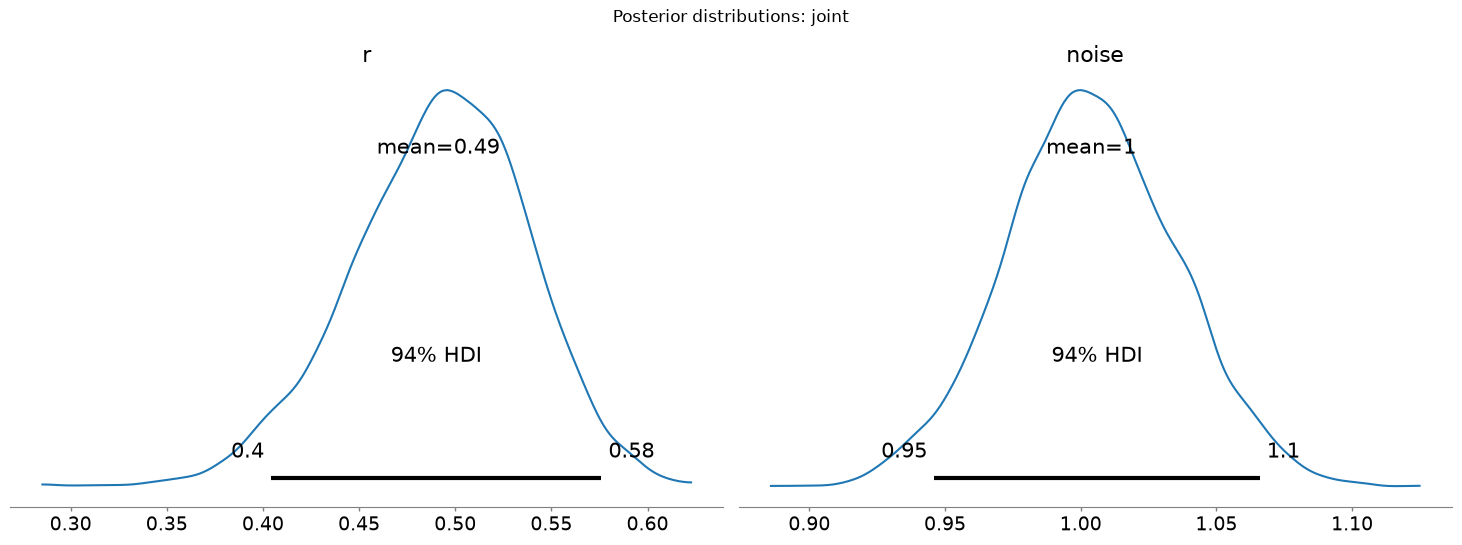

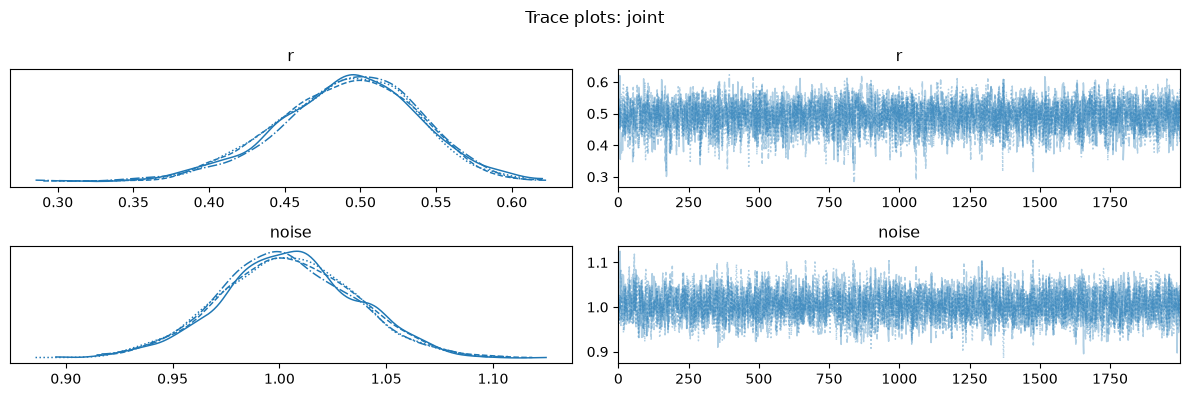

C:\Users\kanci\AppData\Local\Temp\ipykernel_20512\657810364.py:36: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


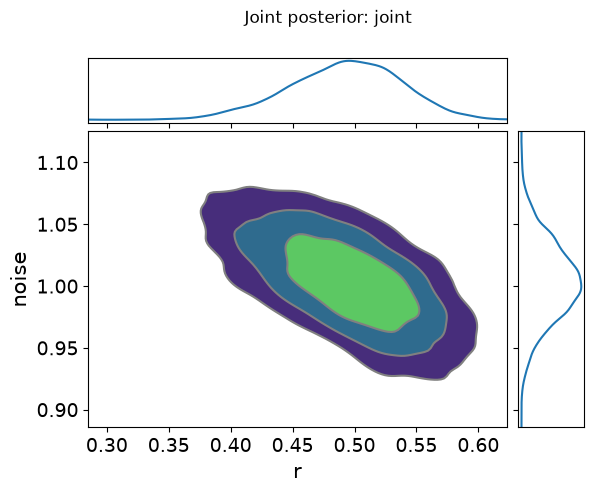

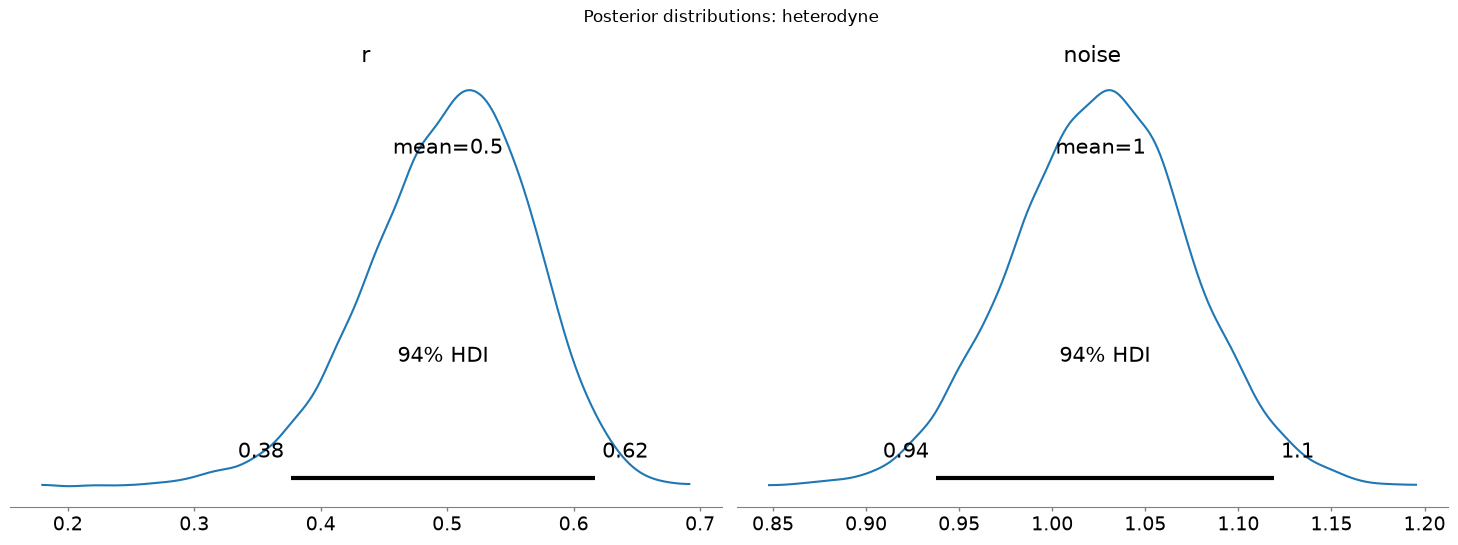

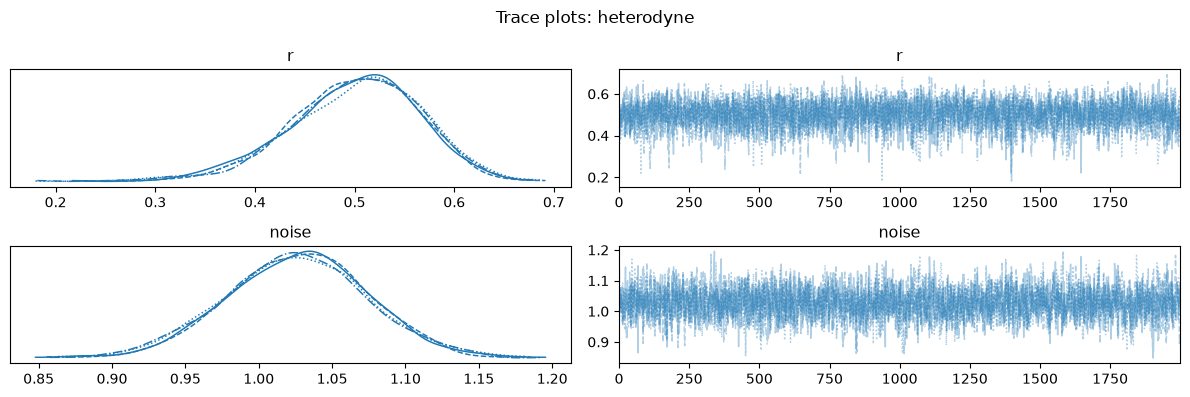

C:\Users\kanci\AppData\Local\Temp\ipykernel_20512\657810364.py:36: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


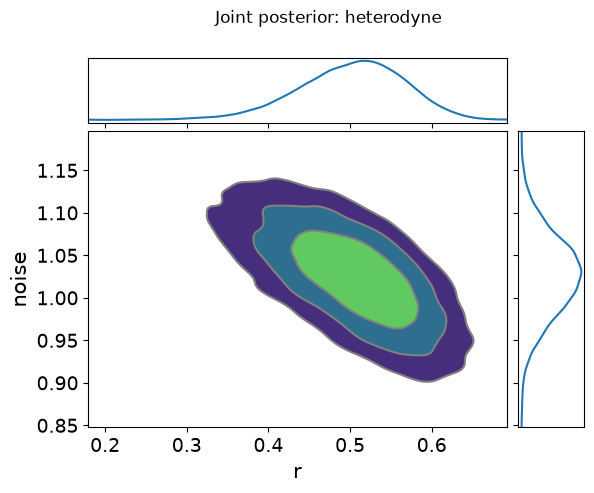

In [18]:
for mt, mcmc in results.items():

    idata = az.from_numpyro(mcmc)

    # Marginal posterior distributions
    az.plot_posterior(
        idata,
        var_names=["r", "noise"],
        ref_val=None,
    )

    plt.suptitle(f"Posterior distributions: {mt}")
    plt.tight_layout()
    plt.show()

    # Trace plots
    az.plot_trace(
        idata,
        var_names=["r", "noise"],
        compact=True,
    )

    plt.suptitle(f"Trace plots: {mt}")
    plt.tight_layout()
    plt.show()

    # Joint posterior: trade-off between r and noise
    az.plot_pair(
        idata,
        var_names=["r", "noise"],
        kind="kde",
        marginals=True,
    )

    plt.suptitle(f"Joint posterior: {mt}")
    plt.tight_layout()
    plt.show()